# Huấn luyện YOLO nhận diện biển số xe (GreenParking) — triển khai trên Raspberry Pi 4 (4 GB)

**Bài toán:** phát hiện vùng biển số trong ảnh cổng vào/ra bãi xe (hệ thống ESP32-CAM + Raspberry Pi 4). Dataset `GreenParking` chỉ có nhãn **bbox biển số** (`location.txt`), **không có nhãn ký tự** → notebook này train **bộ phát hiện biển số (1 class `plate`)**. Bước đọc ký tự (OCR) là bước riêng, chạy trên ảnh đã crop (xem TODO trong `pi_infer.py`).

**Chọn model cho Pi 4:** Ultralytics **YOLO26** (NMS-free, bỏ DFL, thiết kế cho CPU/edge). Notebook train `yolo26n` và `yolo26s`, rồi chọn theo quy tắc *model nhỏ nhất mà mAP50-95 không thua model tốt nhất quá `PICK_MARGIN`* — vì trên Pi 4 độ trễ quan trọng hơn vài phần mười điểm mAP.

**Chuẩn bị trên Kaggle**
1. Upload `GreenParking.zip` thành Kaggle Dataset (Kaggle tự giải nén; notebook xử lý cả trường hợp còn nguyên file zip).
2. Notebook Settings: **Accelerator = GPU (T4 / P100)**, **Internet = On** (để tải trọng số `yolo26*.pt`).
3. Chạy tuần tự từ Cell 0. Đặt `SMOKE_TEST = True` ở Cell 1 để chạy thử nhanh toàn bộ pipeline (vài phút).

**Đầu ra** (`/kaggle/working`): `plate_detector_bundle.zip` gồm `best.pt`, ONNX, NCNN, `model_info.json`, `pi_infer.py`, biểu đồ.

In [1]:
# =====================================================================
# CELL 0: Cài thư viện + seed + platform report (tái lập kết quả)
# =====================================================================
import os, sys, json, time, random, platform, subprocess
import numpy as np

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "ultralytics"], check=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
T0 = time.time()      # mốc bắt đầu - canh quỹ thời gian phiên Kaggle

import torch
torch.manual_seed(SEED)
import ultralytics
from pathlib import Path

OUT = Path("/kaggle/working") if Path("/kaggle").exists() else Path("./work")
OUT.mkdir(parents=True, exist_ok=True)


def platform_report(path=OUT / "platform_report.json"):
    info = {"python": sys.version.split()[0], "os": platform.platform(), "cpu_count": os.cpu_count(),
            "seed": SEED, "ultralytics": ultralytics.__version__, "torch": torch.__version__,
            "cuda_available": bool(torch.cuda.is_available())}
    try:
        import psutil
        info["ram_gb"] = round(psutil.virtual_memory().total / 1e9, 1)
    except Exception:
        pass
    if torch.cuda.is_available():
        info["gpu"] = torch.cuda.get_device_name(0)
        info["gpu_ram_gb"] = round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1)
    Path(path).write_text(json.dumps(info, indent=2))
    return info


PLATFORM_INFO = platform_report()
print(json.dumps(PLATFORM_INFO, indent=2))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{
  "python": "3.13.16",
  "os": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "cpu_count": 4,
  "seed": 42,
  "ultralytics": "8.4.207",
  "torch": "2.11.0+cu130",
  "cuda_available": true,
  "ram_gb": 33.7,
  "gpu": "Tesla T4",
  "gpu_ram_gb": 15.6
}


In [2]:
# =====================================================================
# CELL 1: CẤU HÌNH
# =====================================================================
SMOKE_TEST = False            # True = chạy thử nhanh (ít ảnh, 1 epoch, 1 model) để kiểm tra pipeline

CLASS_NAMES = ["plate"]
IMG_SIZE = 480                # ảnh gốc 472x303 -> 480 gần như không mất chi tiết (biển ~70-85 px)
EXPORT_IMGSZ = [320, 480]     # [cao, rộng] cho model xuất ra: bỏ phần pad thừa, ít điểm ảnh hơn 480x480 (~33%) -> nhanh hơn trên Pi

# Ứng viên theo thứ tự NHỎ -> LỚN. Nếu không tải được yolo26 (ultralytics cũ / không có Internet) sẽ thử bản fallback.
CANDIDATES = ["yolo26n.pt", "yolo26s.pt"]
FALLBACKS = {"yolo26n.pt": "yolo11n.pt", "yolo26s.pt": "yolo11s.pt"}
PICK_MARGIN = 0.010           # chọn model nhỏ nhất có mAP50-95(val) >= (tốt nhất - 0.010)

EPOCHS, BATCH, PATIENCE = 100, 32, 25
SPLIT = {"train": 0.70, "val": 0.15, "test": 0.15}
TIME_BUDGET_H = 3.0           # quỹ thời gian cho phần train (Kaggle tối đa ~12h/phiên)
MIN_BOX_PX = 6                # bỏ box nhỏ hơn 6 px (nhãn hỏng)
CONF_FALLBACK = 0.35          # ngưỡng conf mặc định nếu không tính được từ đường cong F1

DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORKERS = min(4, os.cpu_count() or 1)

if SMOKE_TEST:
    CANDIDATES = CANDIDATES[:1]; EPOCHS, BATCH, PATIENCE = 1, 8, 5; WORKERS = 0
    SMOKE_N_IMAGES = 120

print(f"device={DEVICE} | imgsz={IMG_SIZE} | candidates={CANDIDATES} | smoke={SMOKE_TEST}")

device=0 | imgsz=480 | candidates=['yolo26n.pt', 'yolo26s.pt'] | smoke=False


In [3]:
# =====================================================================
# CELL 2: TÌM DATASET + ĐỌC NHÃN location.txt
# Định dạng mỗi dòng: <tên_ảnh> <số_biển> (x y w h) x số_biển   (x,y = góc trên-trái, đơn vị pixel)
# Đã kiểm tra bằng cách vẽ thử bbox lên ảnh: đúng định dạng top-left + w/h.
# =====================================================================
import zipfile
from PIL import Image

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def find_data_dir():
    roots = [Path(p) for p in [os.environ.get("GP_ROOT", ""), "/kaggle/input", "."] if p]
    for r in roots:                                   # 1) thư mục đã giải nén (có location.txt)
        if r.exists():
            for p in r.rglob("location.txt"):
                return p.parent
    for r in roots:                                   # 2) còn nguyên file zip -> giải nén
        if r.exists():
            for z in r.rglob("*.zip"):
                if "greenparking" in z.name.lower():
                    dst = OUT / "raw"; dst.mkdir(exist_ok=True)
                    with zipfile.ZipFile(z) as zf:
                        zf.extractall(dst)
                    for p in dst.rglob("location.txt"):
                        return p.parent
    raise FileNotFoundError("Không thấy GreenParking (location.txt hoặc GreenParking.zip) trong /kaggle/input. "
                            "Hãy Add Data -> upload dataset.")


DATA_DIR = find_data_dir()
print("DATA_DIR:", DATA_DIR)

issues = []
raw_boxes = {}                       # tên ảnh -> list [x, y, w, h]
for ln in (DATA_DIR / "location.txt").read_text().splitlines():
    t = ln.split()
    if len(t) < 2:
        continue
    name, n = t[0], int(t[1])
    nums = list(map(float, t[2:]))
    if len(nums) != 4 * n:
        issues.append((name, f"số token {len(nums)} != 4*{n}")); continue
    raw_boxes[name] = [nums[i * 4:(i + 1) * 4] for i in range(n)]

images = sorted(p for p in DATA_DIR.iterdir() if p.suffix.lower() in IMG_EXTS)
img_names = {p.name for p in images}
print(f"ảnh: {len(images)} | dòng nhãn: {len(raw_boxes)} | ảnh thiếu nhãn: {len(img_names - set(raw_boxes))} "
      f"| nhãn thiếu ảnh: {len(set(raw_boxes) - img_names)} | dòng lỗi: {len(issues)}")
assert len(images) > 500, "Số ảnh quá ít - kiểm tra lại dataset"

DATA_DIR: /kaggle/input/datasets/nomoref/biensoxe/GreenParking
ảnh: 1748 | dòng nhãn: 1748 | ảnh thiếu nhãn: 0 | nhãn thiếu ảnh: 0 | dòng lỗi: 0


ảnh dùng được: 1748 | tổng box: 1748 | box bị loại: 1
kích thước ảnh: {(472, 303): 1748}
box w (chuẩn hoá): mean=0.165 min=0.121 max=0.206
box h (chuẩn hoá): mean=0.224 min=0.152 max=0.294
tỉ lệ w/h: mean=1.15
ảnh có >1 biển: 0


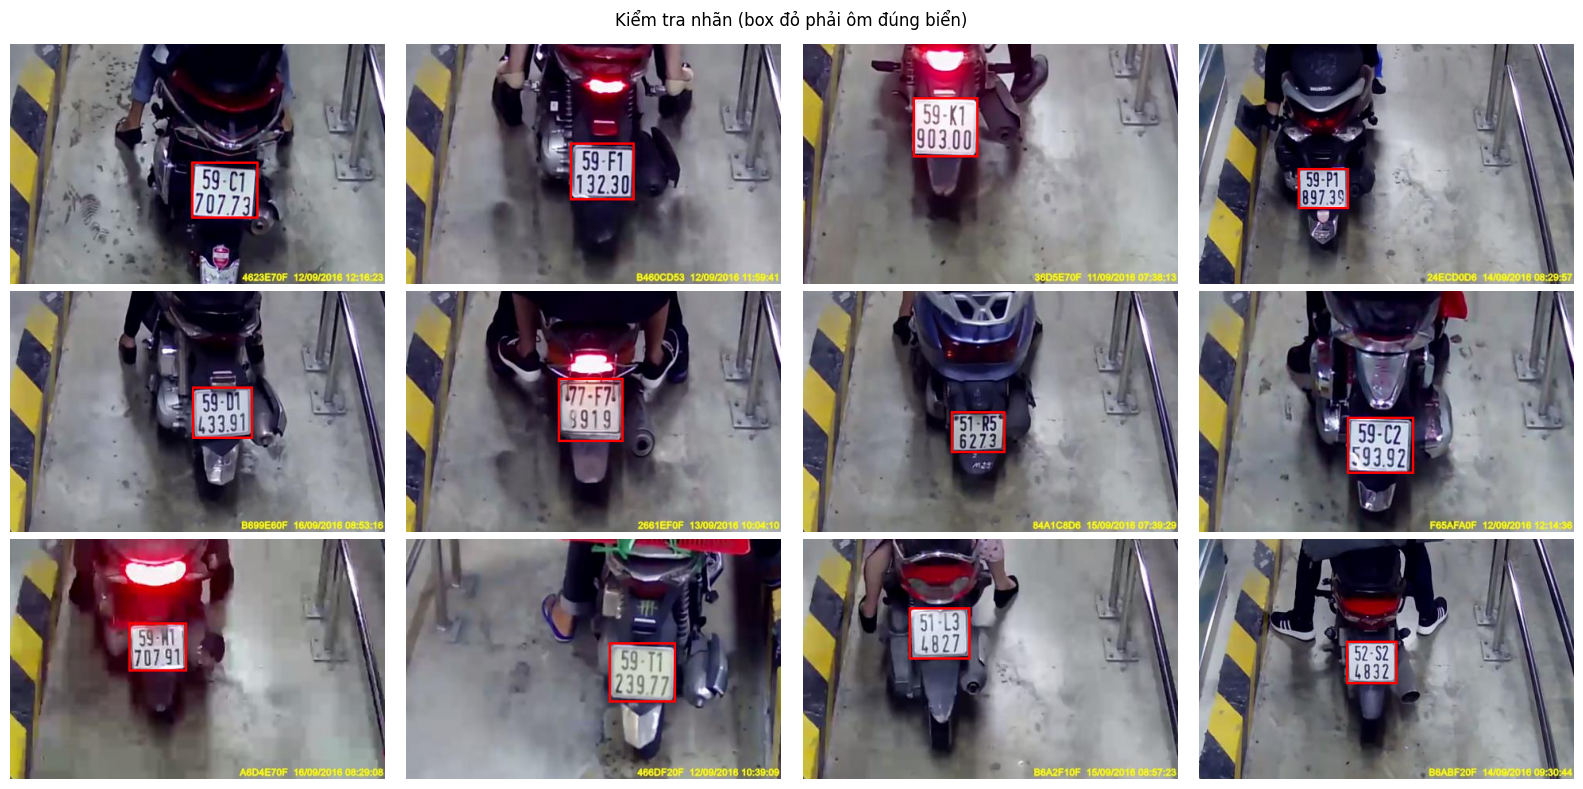

In [4]:
# =====================================================================
# CELL 3: CHUẨN HOÁ NHÃN -> YOLO (xc yc w h chuẩn hoá) + QC + THỐNG KÊ + VẼ THỬ
# QC: cắt box vào trong ảnh, bỏ box suy biến (< MIN_BOX_PX) hoặc ngoài ảnh.
# =====================================================================
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import ImageDraw

records, dropped = [], []
for p in images:
    if p.name not in raw_boxes:
        continue
    with Image.open(p) as im:
        W, H = im.size
    yolo_boxes = []
    for (x, y, w, h) in raw_boxes[p.name]:
        x1, y1, x2, y2 = max(x, 0), max(y, 0), min(x + w, W), min(y + h, H)
        if (x2 - x1) < MIN_BOX_PX or (y2 - y1) < MIN_BOX_PX:
            dropped.append((p.name, x, y, w, h)); continue
        yolo_boxes.append(((x1 + x2) / 2 / W, (y1 + y2) / 2 / H, (x2 - x1) / W, (y2 - y1) / H))
    if yolo_boxes:
        records.append({"name": p.name, "path": str(p), "W": W, "H": H, "boxes": yolo_boxes})

df = pd.DataFrame(records)
if SMOKE_TEST:
    df = df.sample(SMOKE_N_IMAGES, random_state=SEED).reset_index(drop=True)
bx = np.array([b for r in df["boxes"] for b in r])
print(f"ảnh dùng được: {len(df)} | tổng box: {len(bx)} | box bị loại: {len(dropped)}")
print("kích thước ảnh:", df.groupby(["W", "H"]).size().to_dict())
print(f"box w (chuẩn hoá): mean={bx[:,2].mean():.3f} min={bx[:,2].min():.3f} max={bx[:,2].max():.3f}")
print(f"box h (chuẩn hoá): mean={bx[:,3].mean():.3f} min={bx[:,3].min():.3f} max={bx[:,3].max():.3f}")
print(f"tỉ lệ w/h: mean={(bx[:,2]*df['W'].iloc[0]/(bx[:,3]*df['H'].iloc[0])).mean():.2f}")
print("ảnh có >1 biển:", int((df["boxes"].map(len) > 1).sum()))

fig, axs = plt.subplots(3, 4, figsize=(16, 8))
for ax, (_, r) in zip(axs.ravel(), df.sample(12, random_state=1).iterrows()):
    im = Image.open(r["path"]).convert("RGB"); d = ImageDraw.Draw(im)
    for xc, yc, w, h in r["boxes"]:
        d.rectangle([(xc - w / 2) * r["W"], (yc - h / 2) * r["H"], (xc + w / 2) * r["W"], (yc + h / 2) * r["H"]],
                    outline="red", width=3)
    ax.imshow(im); ax.axis("off")
plt.suptitle("Kiểm tra nhãn (box đỏ phải ôm đúng biển)"); plt.tight_layout()
(OUT / "figures").mkdir(exist_ok=True); plt.savefig(OUT / "figures" / "label_check.png", dpi=100); plt.show()

In [5]:
# =====================================================================
# CELL 4: CHIA TRAIN / VAL / TEST THEO NHÓM + GHI DATASET YOLO
# Tên ảnh dạng "0000_00532_b.jpg": dataset KHÔNG có ID xe/phiên chụp, nên dùng tiền tố 4 số đầu làm group
# (cách chia bảo thủ: ảnh cùng tiền tố luôn nằm cùng 1 tập). Chỉ chống được rò rỉ MỘT PHẦN - nếu cùng một xe
# xuất hiện ở nhiều tiền tố khác nhau thì vẫn có thể rò rỉ; mAP val/test nên được xem là cận trên.
# test CHỈ chấm 1 lần ở cuối (Cell 9).
# =====================================================================
import shutil

df["group"] = df["name"].str.split("_").str[0]
groups = df["group"].unique().tolist()
random.Random(SEED).shuffle(groups)
sizes = df.groupby("group").size().to_dict()
total = len(df); targets = {k: v * total for k, v in SPLIT.items()}
assign, counts = {}, {k: 0 for k in SPLIT}
order = ["test", "val", "train"]
for g in groups:                                     # lấp test -> val -> train theo chỉ tiêu số ảnh
    for k in order:
        if k == "train" or counts[k] + sizes[g] <= targets[k] * 1.05:
            assign[g] = k; counts[k] += sizes[g]; break
df["split"] = df["group"].map(assign)

DS = OUT / "ds"
if DS.exists():
    shutil.rmtree(DS)
for s in SPLIT:
    (DS / "images" / s).mkdir(parents=True); (DS / "labels" / s).mkdir(parents=True)
for _, r in df.iterrows():
    shutil.copy2(r["path"], DS / "images" / r["split"] / r["name"])
    lines = [f"0 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}" for xc, yc, w, h in r["boxes"]]
    (DS / "labels" / r["split"] / (Path(r["name"]).stem + ".txt")).write_text("\n".join(lines))

DATA_YAML = DS / "data.yaml"
DATA_YAML.write_text(f"path: {DS}\ntrain: images/train\nval: images/val\ntest: images/test\n"
                     f"nc: {len(CLASS_NAMES)}\nnames: {CLASS_NAMES}\n")
tab = df.groupby("split").agg(anh=("name", "count"), nhom=("group", "nunique"), box=("boxes", lambda s: sum(len(b) for b in s)))
print(tab.loc[[k for k in SPLIT]])
assert set(df[df.split == "train"].group).isdisjoint(df[df.split != "train"].group), "rò rỉ group!"
print("DATA_YAML:", DATA_YAML)

        anh  nhom   box
split                  
train  1198   192  1198
val     275    59   275
test    275    57   275
DATA_YAML: /kaggle/working/ds/data.yaml


In [6]:
# =====================================================================
# CELL 5: HÀM TRAIN / ĐÁNH GIÁ / ĐO ĐỘ TRỄ
# =====================================================================
import gc
from ultralytics import YOLO

RUNS = OUT / "runs"; RUNS.mkdir(exist_ok=True)


def resolve_weights(name):
    """Thử tải trọng số pretrained; lỗi (phiên bản cũ / không Internet) -> dùng bản fallback YOLO11."""
    try:
        YOLO(name); return name
    except Exception as e:
        fb = FALLBACKS.get(name)
        print(f"[!] Không nạp được {name} ({type(e).__name__}: {str(e)[:120]}). Fallback -> {fb}")
        if fb is None:
            raise
        YOLO(fb); return fb


def make_time_guard(deadline_ts):
    def _cb(trainer):
        if time.time() > deadline_ts:
            print("[time-guard] hết quỹ thời gian -> dừng sớm, giữ best.pt")
            trainer.stop = True
    return _cb


# Camera cổng cố định, biển xe lớn -> augment vừa phải: KHÔNG lật ngang (chữ bị đảo), xoay nhẹ, đổi sáng/chói mạnh
# (hầm xe thiếu sáng, đèn xe chói), mosaic tắt ở 10 epoch cuối.
TRAIN_CFG = dict(
    imgsz=IMG_SIZE, epochs=EPOCHS, batch=BATCH, patience=PATIENCE, seed=SEED, workers=WORKERS, device=DEVICE,
    cos_lr=True, close_mosaic=10, mosaic=1.0, mixup=0.0, scale=0.4, translate=0.1, degrees=5.0, fliplr=0.0,
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.45, erasing=0.2, amp=True, plots=True, deterministic=False,
)


def train_one(weights, tag, deadline):
    model = YOLO(weights)
    model.add_callback("on_fit_epoch_end", make_time_guard(deadline))
    t = time.time()
    model.train(data=str(DATA_YAML), project=str(RUNS), name=tag, exist_ok=True, **TRAIN_CFG)
    run_dir = Path(model.trainer.save_dir)
    dt = time.time() - t
    del model; gc.collect(); torch.cuda.empty_cache()
    return run_dir, run_dir / "weights" / "best.pt", dt


def evaluate(weights, split="val", imgsz=IMG_SIZE, device=DEVICE, batch=16, name=None):
    m = YOLO(str(weights), task="detect")
    res = m.val(data=str(DATA_YAML), split=split, imgsz=imgsz, batch=batch, conf=0.001, iou=0.6, device=device,
                plots=False, verbose=False, workers=WORKERS, project=str(RUNS), name=name or f"eval_{split}", exist_ok=True)
    out = dict(map50=float(res.box.map50), map5095=float(res.box.map), p=float(res.box.mp), r=float(res.box.mr))
    try:   # ngưỡng conf tối ưu theo F1
        f1 = np.asarray(res.box.f1_curve).mean(0)
        out["best_f1"] = float(f1.max()); out["best_f1_conf"] = float(np.asarray(res.box.px)[int(f1.argmax())])
    except Exception:
        pass
    del m; gc.collect(); torch.cuda.empty_cache()
    return out


def latency_ms(model_path, imgsz, n=40, threads=4):
    """Độ trễ end-to-end (tiền xử lý + suy luận + hậu xử lý) trên CPU, 1 ảnh/lần, có warm-up, lấy median.
    LƯU Ý: CPU Kaggle nhanh hơn Raspberry Pi 4 nhiều lần -> chỉ dùng để SO SÁNH TƯƠNG ĐỐI giữa các định dạng/model."""
    torch.set_num_threads(threads)
    m = YOLO(str(model_path), task="detect")
    imgs = sorted((DS / "images" / "val").glob("*"))[:n]
    for p in imgs[:5]:
        m.predict(str(p), imgsz=imgsz, device="cpu", verbose=False)
    ts = []
    for p in imgs:
        t = time.perf_counter(); m.predict(str(p), imgsz=imgsz, device="cpu", verbose=False)
        ts.append((time.perf_counter() - t) * 1000)
    del m; gc.collect()
    return round(float(np.median(ts)), 1)


print("Đã nạp hàm train/evaluate/latency.")

Đã nạp hàm train/evaluate/latency.


In [7]:
# =====================================================================
# CELL 6: TRAIN CÁC ỨNG VIÊN (nhỏ -> lớn)
# =====================================================================
deadline = T0 + TIME_BUDGET_H * 3600
results = {}      # tên -> dict
for i, cand in enumerate(CANDIDATES):
    if time.time() > deadline:
        print(f"[!] Hết quỹ thời gian, bỏ qua {cand}"); break
    w = resolve_weights(cand)
    tag = Path(w).stem + "_plate"
    print(f"\n{'=' * 70}\nTRAIN {tag}  (còn {(deadline - time.time()) / 60:.0f} phút)\n{'=' * 70}")
    run_dir, best, dt = train_one(w, tag, deadline)
    results[tag] = dict(weights_init=w, run_dir=str(run_dir), best=str(best), train_min=round(dt / 60, 1))
    print(f"-> {tag}: train {dt / 60:.1f} phút, best={best}")


TRAIN yolo26n_plate  (còn 176 phút)
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/ds/data.yaml, degrees=5.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.2, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.6, hsv_v=0.45, imgsz=480, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_plate, nbs=64,

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100       2.9G     0.7086      1.118   0.004785         28        480: 100% ━━━━━━━━━━━━ 38/38 6.2it/s 6.2s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.7it/s 0.9s0.3s
                   all        275        275          1          1      0.995      0.816

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/100       2.9G     0.7343      0.573   0.004956         27        480: 100% ━━━━━━━━━━━━ 38/38 6.2it/s 6.1s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.6it/s 0.9s0.3s
                   all        275        275          1          1      0.995       0.87

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/100       2.9G      0.717     0.4812    0.00488         28        480: 100% ━━━━━━━━━━━━ 38/38 6.5it/s 5.8s0.3s
                 Class     Images  Instances  

In [8]:
# =====================================================================
# CELL 7: SO SÁNH TRÊN VAL + CHỌN MODEL CHO PI 4
# Quy tắc: model NHỎ NHẤT có mAP50-95(val) >= (tốt nhất - PICK_MARGIN).
# Lưu ý: bài toán 1 class, biển to -> mAP50 gần như bão hoà; mAP50-95 (độ khít box) mới phân biệt được model.
# =====================================================================
rows = []
for tag, r in results.items():
    m = evaluate(r["best"], "val", name=f"val_{tag}")
    r["val"] = m
    n_params = sum(p.numel() for p in YOLO(r["best"]).model.parameters())
    r["params_M"] = round(n_params / 1e6, 2)
    r["cpu_ms_pt"] = latency_ms(r["best"], IMG_SIZE)
    rows.append(dict(model=tag, params_M=r["params_M"], mAP50=round(m["map50"], 4), mAP50_95=round(m["map5095"], 4),
                     P=round(m["p"], 4), R=round(m["r"], 4), cpu_ms_pt=r["cpu_ms_pt"], train_min=r["train_min"]))
cmp_df = pd.DataFrame(rows); print(cmp_df.to_string(index=False))

best_map = max(r["val"]["map5095"] for r in results.values())
CHOSEN = next(t for t, r in results.items() if r["val"]["map5095"] >= best_map - PICK_MARGIN)   # dict giữ thứ tự nhỏ -> lớn
print(f"\n==> CHỌN: {CHOSEN} (mAP50-95 val = {results[CHOSEN]['val']['map5095']:.4f}, tốt nhất = {best_map:.4f}, margin = {PICK_MARGIN})")
if all(r["val"]["map50"] > 0.99 for r in results.values()):
    print("[i] mAP50 > 0.99 ở mọi model: val gần bão hoà -> hãy kiểm tra thêm bằng ảnh thật từ ESP32-CAM của bạn trước khi kết luận.")
cmp_df.to_csv(OUT / "model_comparison_val.csv", index=False)

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 781.9±152.1 MB/s, size: 18.2 KB)
val: Scanning /kaggle/working/ds/labels/val.cache... 275 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 275/275 82.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 13.0it/s 1.4s0.1s
                   all        275        275          1          1      0.995      0.936
Speed: 0.4ms preprocess, 2.0ms inference, 0.0ms loss, 0.8ms postprocess per image
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 691.8±179.3 MB/s, size: 16.3 KB)
val: Scanning /kaggle/working/ds/labels/val.cache... 275 images,

Ngưỡng conf dùng khi triển khai: 0.60
VAL @conf=0.60, IoU>=0.5: TP=275 FP=0 FN=0 | precision=1.000 recall=1.000 | ảnh lỗi: 0/275


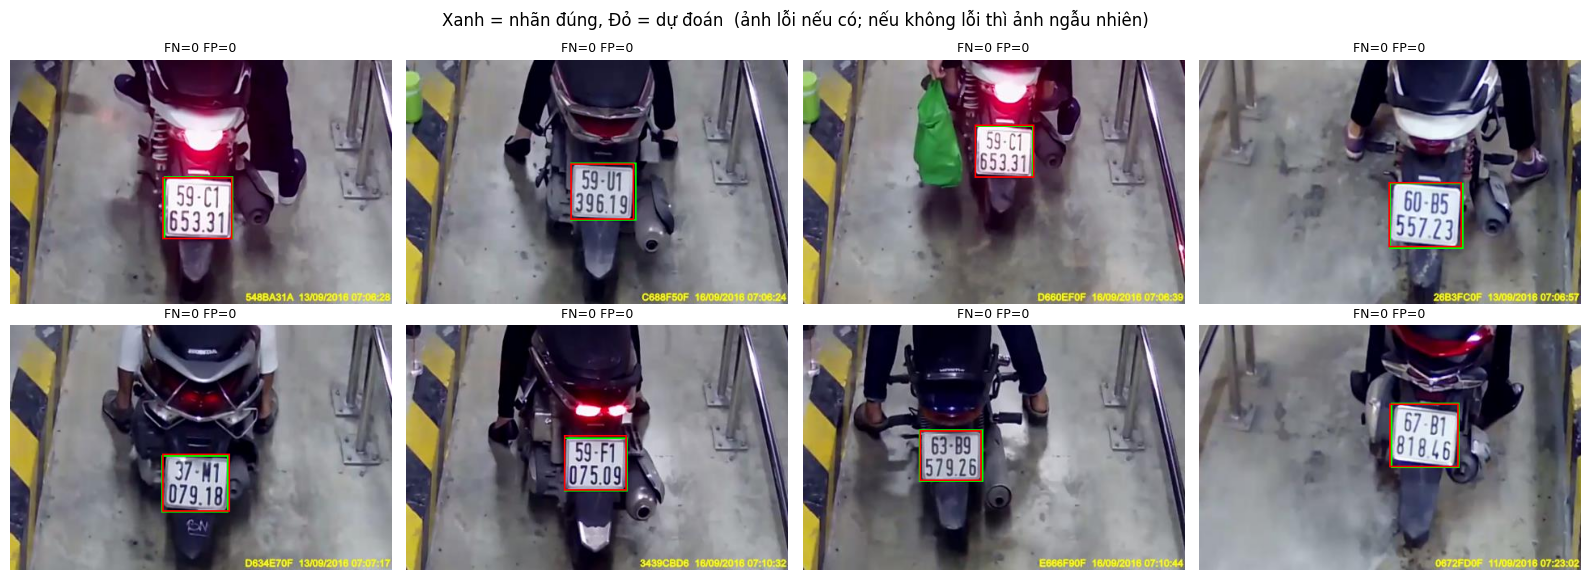

20512

In [9]:
# =====================================================================
# CELL 8: PHÂN TÍCH LỖI TRÊN VAL (FN/FP theo IoU>=0.5) + ẢNH DỰ ĐOÁN
# =====================================================================
BEST_PT = results[CHOSEN]["best"]
CONF = results[CHOSEN]["val"].get("best_f1_conf", CONF_FALLBACK)
CONF = float(min(max(CONF, 0.15), 0.60))        # kẹp về khoảng hợp lý
print(f"Ngưỡng conf dùng khi triển khai: {CONF:.2f}")


def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(ix2 - ix1, 0) * max(iy2 - iy1, 0)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def read_gt(img_path, W, H):
    lp = DS / "labels" / img_path.parent.name / (img_path.stem + ".txt")
    out = []
    for ln in lp.read_text().splitlines():
        _, xc, yc, w, h = map(float, ln.split())
        out.append(((xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H))
    return out


model = YOLO(BEST_PT)
val_imgs = sorted((DS / "images" / "val").glob("*"))
tp = fp = fn = 0; bad = []
for p in val_imgs:
    r = model.predict(str(p), imgsz=IMG_SIZE, conf=CONF, device=DEVICE, verbose=False)[0]
    H, W = r.orig_shape
    preds = [tuple(b) for b in r.boxes.xyxy.cpu().numpy().tolist()]
    gts = read_gt(p, W, H); used = set(); e_fn = e_fp = 0
    for g in gts:
        best_j, best_i = -1, 0
        for j, pr in enumerate(preds):
            if j not in used and iou(g, pr) > best_i:
                best_i, best_j = iou(g, pr), j
        if best_i >= 0.5:
            tp += 1; used.add(best_j)
        else:
            fn += 1; e_fn += 1
    e_fp = len(preds) - len(used); fp += e_fp
    if e_fn or e_fp:
        bad.append((p, e_fn, e_fp, preds, gts))
prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
print(f"VAL @conf={CONF:.2f}, IoU>=0.5: TP={tp} FP={fp} FN={fn} | precision={prec:.3f} recall={rec:.3f} | ảnh lỗi: {len(bad)}/{len(val_imgs)}")


def draw(p, preds, gts):
    im = Image.open(p).convert("RGB"); d = ImageDraw.Draw(im)
    for g in gts:
        d.rectangle(g, outline="lime", width=2)
    for b in preds:
        d.rectangle(b, outline="red", width=2)
    return im


show = bad[:8] if bad else [(p, 0, 0, [], []) for p in val_imgs[:8]]
fig, axs = plt.subplots(2, 4, figsize=(16, 6))
for ax, (p, e_fn, e_fp, preds, gts) in zip(axs.ravel(), show):
    if not bad:
        r = model.predict(str(p), imgsz=IMG_SIZE, conf=CONF, device=DEVICE, verbose=False)[0]
        preds = [tuple(b) for b in r.boxes.xyxy.cpu().numpy().tolist()]; gts = read_gt(p, *r.orig_shape[::-1])
    ax.imshow(draw(p, preds, gts)); ax.set_title(f"FN={e_fn} FP={e_fp}", fontsize=9); ax.axis("off")
plt.suptitle("Xanh = nhãn đúng, Đỏ = dự đoán  (ảnh lỗi nếu có; nếu không lỗi thì ảnh ngẫu nhiên)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "val_errors.png", dpi=100); plt.show()
del model; gc.collect()

Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 533.2±183.3 MB/s, size: 16.7 KB)
val: Scanning /kaggle/working/ds/labels/test... 275 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 275/275 1.3Kit/s 0.2s<0.0s
val: New cache created: /kaggle/working/ds/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 12.5it/s 1.4s0.1s
                   all        275        275          1          1      0.995      0.919
Speed: 0.4ms preprocess, 1.9ms inference, 0.0ms loss, 0.9ms postprocess per image
TEST: {'map50': 0.995, 'map5095': 0.9191, 'p': 0.9998, 'r': 1.0, 'best_f1': 1.0, 'best_f1_conf': 0.9079}


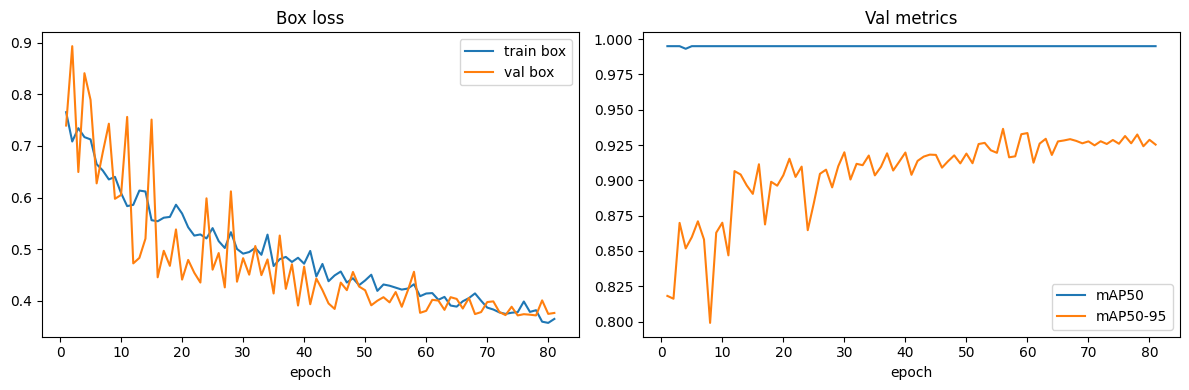

In [10]:
# =====================================================================
# CELL 9: ĐÁNH GIÁ TEST (CHẤM ĐÚNG 1 LẦN) + ĐƯỜNG CONG HUẤN LUYỆN
# =====================================================================
TEST_METRICS = evaluate(BEST_PT, "test", name="test_final")
print("TEST:", {k: round(v, 4) for k, v in TEST_METRICS.items()})

h = pd.read_csv(Path(results[CHOSEN]["run_dir"]) / "results.csv"); h.columns = [c.strip() for c in h.columns]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["epoch"], h["train/box_loss"], label="train box"); ax[0].plot(h["epoch"], h["val/box_loss"], label="val box")
ax[0].set_title("Box loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(h["epoch"], h["metrics/mAP50(B)"], label="mAP50"); ax[1].plot(h["epoch"], h["metrics/mAP50-95(B)"], label="mAP50-95")
ax[1].set_title("Val metrics"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT / "figures" / "training_history.png", dpi=100); plt.show()

In [11]:
# =====================================================================
# CELL 10: XUẤT MODEL CHO PI 4 (ONNX + NCNN, FP32) + KIỂM CHỨNG TƯƠNG ĐƯƠNG + ĐO ĐỘ TRỄ TƯƠNG ĐỐI
# - FP32 (half=False): Cortex-A72 của Pi 4 không có số học FP16 -> FP16 không nhanh hơn, chỉ thêm rủi ro.
# - YOLO26 là NMS-free (end-to-end): đầu ra đã là danh sách box cuối cùng, không cần NMS ở phía Pi.
# - NCNN là định dạng Ultralytics khuyên dùng cho Raspberry Pi (CPU ARM).
# =====================================================================
EXPORTS = {}
pt_model = YOLO(BEST_PT)
exp_imgsz = EXPORT_IMGSZ
for fmt in ["onnx", "ncnn"]:
    try:
        EXPORTS[fmt] = pt_model.export(format=fmt, imgsz=exp_imgsz, half=False, device="cpu")
    except Exception as e:
        print(f"[!] Export {fmt} với imgsz={exp_imgsz} lỗi ({type(e).__name__}: {str(e)[:150]}). Thử lại imgsz={IMG_SIZE}")
        exp_imgsz = IMG_SIZE
        try:
            EXPORTS[fmt] = pt_model.export(format=fmt, imgsz=exp_imgsz, half=False, device="cpu")
        except Exception as e2:
            print(f"[!!] Export {fmt} vẫn lỗi: {e2}")
print("Đã xuất:", EXPORTS, "| imgsz xuất:", exp_imgsz)

PARITY, LAT = {}, {"pt": latency_ms(BEST_PT, IMG_SIZE)}
for fmt, path in EXPORTS.items():
    try:
        PARITY[fmt] = evaluate(path, "val", imgsz=exp_imgsz, device="cpu", batch=1, name=f"val_{fmt}")
        LAT[fmt] = latency_ms(path, exp_imgsz)
    except Exception as e:
        print(f"[!] Kiểm chứng {fmt} lỗi: {type(e).__name__}: {str(e)[:150]}")

pt_val = results[CHOSEN]["val"]
print(f"\n{'định dạng':<8}{'mAP50':<9}{'mAP50-95':<10}{'ms/ảnh (CPU Kaggle, tương đối)':<34}")
print(f"{'pt':<8}{pt_val['map50']:<9.4f}{pt_val['map5095']:<10.4f}{LAT['pt']:<34}")
for fmt, m in PARITY.items():
    d = m["map5095"] - pt_val["map5095"]
    flag = "" if abs(d) <= 0.01 else "   <-- LỆCH > 1 điểm, kiểm tra lại export"
    print(f"{fmt:<8}{m['map50']:<9.4f}{m['map5095']:<10.4f}{LAT.get(fmt, '-'):<34}(Δ mAP50-95 so với pt = {d:+.4f}){flag}")

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 2.0 GFLOPs

PyTorch: starting from '/kaggle/working/runs/yolo26n_plate/weights/best.pt' with input shape (1, 3, 320, 480) BCHW and output shape(s) (1, 5, 3150) (5.2 MB)
requirements: Ultralytics requirements ['onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 520ms
Prepared 2 packages in 736ms
Installed 2 packages in 14ms
 + onnxruntime==1.31.1
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 1.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with o

pnnxparam = /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model/model.pnnx.param
pnnxbin = /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model/model.pnnx.bin
pnnxpy = /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model/model_pnnx.py
pnnxonnx = /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model/model.pnnx.onnx
ncnnparam = /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model/model.ncnn.param
ncnnbin = /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model/model.ncnn.bin
ncnnpy = /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model/model_ncnn.py
fp16 = 0
optlevel = 2
device = cpu
inputshape = [1,3,320,480]f32
inputshape2 = 
input = 
input2 = 
customop = 
moduleop = 
get inputshape from traced inputs
inputshape = [1,3,320,480]f32
############# pass_level0
inline module = torch.nn.modules.linear.Identity
inline module = ultralytics.nn.modules.block.Attention
inline module = ultralytics.nn.modules.block.Bottleneck
inline module = ultralytics.nn.mo

NCNN: export success ✅ 6.3s, saved as '/kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model' (9.3 MB)

Export complete (6.6s)
Results saved to /kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model
Predict:         yolo predict task=detect model=/kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model imgsz=320,480 
Validate:        yolo val task=detect model=/kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model imgsz=320,480 data=/kaggle/working/ds/data.yaml 
Visualize:       https://netron.app
Đã xuất: {'onnx': '/kaggle/working/runs/yolo26n_plate/weights/best.onnx', 'ncnn': '/kaggle/working/runs/yolo26n_plate/weights/best_ncnn_model'} | imgsz xuất: [320, 480]
WARNING ⚠️ updating to 'imgsz=480'. 'train' and 'val' imgsz must be an integer, while 'predict' and 'export' imgsz may be a [h, w] list or an integer, i.e. 'yolo export imgsz=640,480' or 'yolo export imgsz=640'
Ultralytics 8.4.207 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
Loading /kaggle

In [12]:
# =====================================================================
# CELL 11: SCRIPT CHẠY TRÊN PI 4 + ĐÓNG GÓI KẾT QUẢ
# =====================================================================
PI_SCRIPT = r'''"""pi_infer.py - phát hiện biển số trên Raspberry Pi 4 (Raspberry Pi OS 64-bit, Python 3.9+).

Cài đặt:   pip install ultralytics ncnn opencv-python-headless
Chạy thử:  python pi_infer.py --model plate_ncnn_model --source ./anh_thu --save-crops ./crops
           python pi_infer.py --model plate_ncnn_model --source http://<IP_ESP32_CAM>:81/stream --save-crops ./crops
"""
import argparse, time
from pathlib import Path
import cv2
from ultralytics import YOLO

CONF_DEFAULT = __CONF__          # ngưỡng tối ưu theo F1 trên tập val
IMGSZ = __IMGSZ__               # [cao, rong] hoac so nguyen; phai khop voi luc xuat model
CROP_MARGIN = 0.08              # nới box 8% mỗi phía để OCR không bị cắt mất ký tự sát mép
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}


def crop_with_margin(img, xyxy, margin=CROP_MARGIN):
    h, w = img.shape[:2]
    x1, y1, x2, y2 = xyxy
    mx, my = (x2 - x1) * margin, (y2 - y1) * margin
    x1, y1, x2, y2 = int(max(x1 - mx, 0)), int(max(y1 - my, 0)), int(min(x2 + mx, w)), int(min(y2 + my, h))
    return img[y1:y2, x1:x2]


def read_plate_text(crop):
    # TODO: chưa cài OCR. Dataset GreenParking không có nhãn ký tự nên notebook này chỉ train bộ PHÁT HIỆN biển.
    # Gắn bộ OCR nhẹ (chạy trên ảnh crop) vào đây, ví dụ model OCR biển số đã train riêng hoặc OCR chạy CPU.
    return None


def frames(source):
    p = Path(source)
    if p.is_dir() or p.suffix.lower() in IMG_EXTS:
        files = sorted(q for q in p.iterdir() if q.suffix.lower() in IMG_EXTS) if p.is_dir() else [p]
        for f in files:
            yield f.name, cv2.imread(str(f))
    else:                                    # luồng video / MJPEG của ESP32-CAM / webcam
        cap = cv2.VideoCapture(int(source) if source.isdigit() else source)
        i = 0
        while cap.isOpened():
            ok, frm = cap.read()
            if not ok:
                break
            yield f"frame_{i:06d}", frm; i += 1
        cap.release()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", required=True)
    ap.add_argument("--source", required=True)
    ap.add_argument("--conf", type=float, default=CONF_DEFAULT)
    ap.add_argument("--save-crops", default="")
    a = ap.parse_args()

    model = YOLO(a.model, task="detect")
    if a.save_crops:
        Path(a.save_crops).mkdir(parents=True, exist_ok=True)
    for name, img in frames(a.source):
        if img is None:
            continue
        t = time.perf_counter()
        r = model.predict(img, imgsz=IMGSZ, conf=a.conf, device="cpu", verbose=False)[0]
        ms = (time.perf_counter() - t) * 1000
        for k, b in enumerate(r.boxes.xyxy.cpu().numpy().tolist()):
            crop = crop_with_margin(img, b)
            text = read_plate_text(crop)
            conf = float(r.boxes.conf[k])
            print(f"{name}: plate#{k} conf={conf:.2f} box={[round(v) for v in b]} text={text} ({ms:.0f} ms)")
            if a.save_crops and crop.size:
                cv2.imwrite(str(Path(a.save_crops) / f"{Path(name).stem}_{k}.jpg"), crop)
        if not len(r.boxes):
            print(f"{name}: không thấy biển ({ms:.0f} ms)")


if __name__ == "__main__":
    main()
'''
PI_SCRIPT = PI_SCRIPT.replace("__CONF__", f"{CONF:.2f}").replace("__IMGSZ__", repr(exp_imgsz))

BUNDLE = OUT / "bundle"
if BUNDLE.exists():
    shutil.rmtree(BUNDLE)
BUNDLE.mkdir()
shutil.copy2(BEST_PT, BUNDLE / "best.pt")
for fmt, path in EXPORTS.items():
    path = Path(path)
    if path.is_dir():
        shutil.copytree(path, BUNDLE / "plate_ncnn_model")
    else:
        shutil.copy2(path, BUNDLE / "plate.onnx")
(BUNDLE / "pi_infer.py").write_text(PI_SCRIPT, encoding="utf-8")
for f in (OUT / "figures").glob("*.png"):
    shutil.copy2(f, BUNDLE / f.name)
cmp_df.to_csv(BUNDLE / "model_comparison_val.csv", index=False)

info = dict(
    task="license plate detection (1 class)", dataset="GreenParking", classes=CLASS_NAMES,
    chosen=CHOSEN, init_weights=results[CHOSEN]["weights_init"], train_imgsz=IMG_SIZE, export_imgsz=exp_imgsz,
    conf_threshold=CONF, val=pt_val, test=TEST_METRICS, export_parity_val=PARITY, cpu_latency_ms_kaggle_relative=LAT,
    split_images=tab["anh"].to_dict(), train_cfg={k: (v if isinstance(v, (int, float, str, bool)) else str(v)) for k, v in TRAIN_CFG.items()},
    platform=PLATFORM_INFO, note="Độ trễ đo trên CPU Kaggle, KHÔNG phải Raspberry Pi 4; hãy benchmark lại trên Pi.",
    todo=["OCR ký tự biển số (chưa có nhãn ký tự)", "Kiểm tra lại bằng ảnh thật từ ESP32-CAM tại cổng", "Benchmark độ trễ thật trên Pi 4"],
)
(BUNDLE / "model_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False))
zip_path = shutil.make_archive(str(OUT / "plate_detector_bundle"), "zip", BUNDLE)
print("Đã đóng gói:", zip_path)
print(sorted(p.name for p in BUNDLE.iterdir()))
print(f"Tổng thời gian chạy: {(time.time() - T0) / 60:.1f} phút")

Đã đóng gói: /kaggle/working/plate_detector_bundle.zip
['best.pt', 'label_check.png', 'model_comparison_val.csv', 'model_info.json', 'pi_infer.py', 'plate.onnx', 'plate_ncnn_model', 'training_history.png', 'val_errors.png']
Tổng thời gian chạy: 35.0 phút


## Triển khai trên Raspberry Pi 4

1. Tải `plate_detector_bundle.zip` ở tab **Output**, giải nén lên Pi.
2. Trên Pi (OS 64-bit): `pip install ultralytics ncnn opencv-python-headless`.
3. Chạy thử: `python pi_infer.py --model plate_ncnn_model --source ./anh_thu --save-crops ./crops`.
4. **Benchmark lại độ trễ trên chính Pi 4** (số ms trong notebook đo trên CPU Kaggle, chỉ để so sánh tương đối).
5. Nên gom thêm ảnh thật từ ESP32-CAM tại cổng (góc, ánh sáng, độ nén JPEG khác GreenParking) rồi train bổ sung — dataset GreenParking chụp từ một góc/camera cố định nên mAP cao chưa đảm bảo chạy tốt ở hiện trường.

**Chưa làm (TODO):** OCR đọc ký tự biển số — cần nhãn ký tự hoặc bộ OCR riêng chạy trên ảnh crop.